## Установка датасета

In [65]:
import kagglehub
path = kagglehub.dataset_download("roshan1809/legal-case-reports", output_dir='data')
print(path)

Using Colab cache for faster access to the 'legal-case-reports' dataset.
/kaggle/input/legal-case-reports


## Установка пакета nltk и списка стоп слов

In [66]:
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Импорт зависимостей

In [86]:
import os
from xml.etree import ElementTree
import re
from lxml import html
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

## Пайплайн парсинга и подготовки датасета

- Исходный датасет разделен на три папки, соответствующий определенному типу задачи. Была выбрана задача классификации типа цитирования в юридическом деле

- Пайплайн исправляет некорректный формат xml файлов и по тегам собирает датасет

In [87]:
def xml_file_parse(filepath: str):
    with open(filepath, 'r', encoding='windows-1252') as file:
        text = file.read()
    text = re.sub(r'<citation\s+?"id=([^?"]+?)"', r'<citation id="\1"', text)
    return html.fromstring(text)

def get_data(dir:str, cls_dir:str) -> pd.DataFrame:
    class_dir = os.path.join(dir, cls_dir)
    arr = []
    for file in os.listdir(class_dir):
        file_path = os.path.join(class_dir, file)
        tree = xml_file_parse(file_path)
        block = tree.find('citations')
        doc_id = os.path.splitext(file)[0]
        for i in block.findall('citation'):
            cls = i.find('class')
            if cls is None:
                continue
            cls = cls.text.strip() if cls is not None and cls.text else None

            txt = i.find('text')
            txt = txt.text.strip() if txt is not None and txt.text else None

            to_case = i.find('tocase')
            to_case = to_case.text.strip() if to_case is not None and to_case.text else None

            cit_id = i.get('id')
            arr.append(
                {
                    'doc_id': doc_id,
                    'cit_id': cit_id,
                    'class': cls,
                    'case': to_case,
                    'text': txt,
                }
            )
    df = pd.DataFrame(arr)
    return df


## Задание 1

### Разделение датасета на обучающую и тестовую выборки.
По заданию

In [88]:
df = get_data('/kaggle/input/legal-case-reports/corpus', 'citations_class')
y = df['class']
X = df.drop('class', axis='columns')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## Задание 2

### Исследование структуры данных

- Для упрощение подсчета длины в словах воспользовался простым сплитом

- Видны "выбросы" с большим количеством слов в тексте

- Большая часть текстов содержит менее 5000 слов

- Наиболее часто встречающееся стоп-слово - "the" более 700 тыс повторений

- Большинство стоп-слов повторяется менее 150 тыс раз



Всего документов: 20202
Средняя длина текстов в символах: 2689
Средняя длина текстов в словах: 457


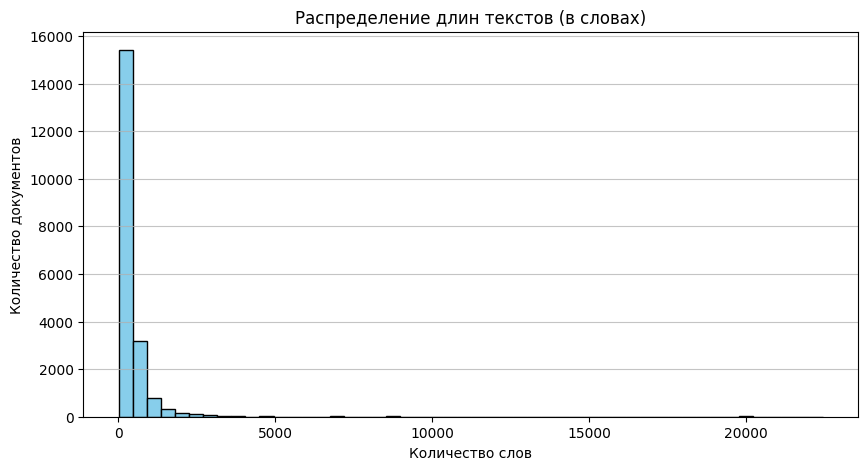

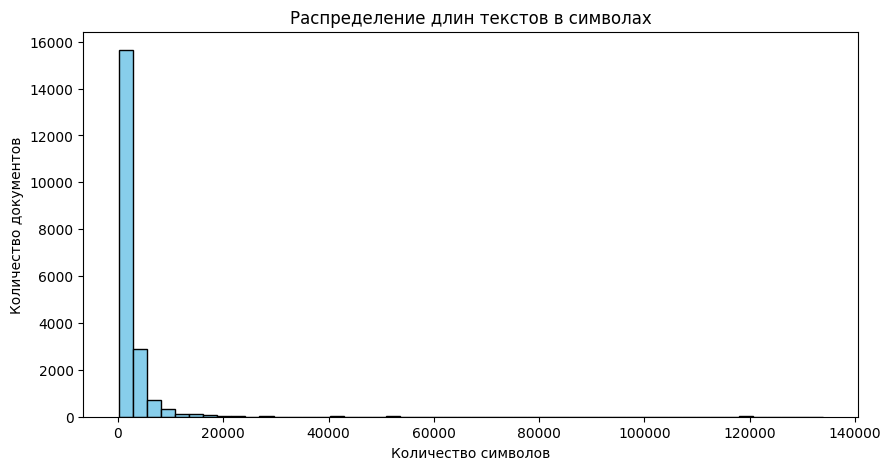

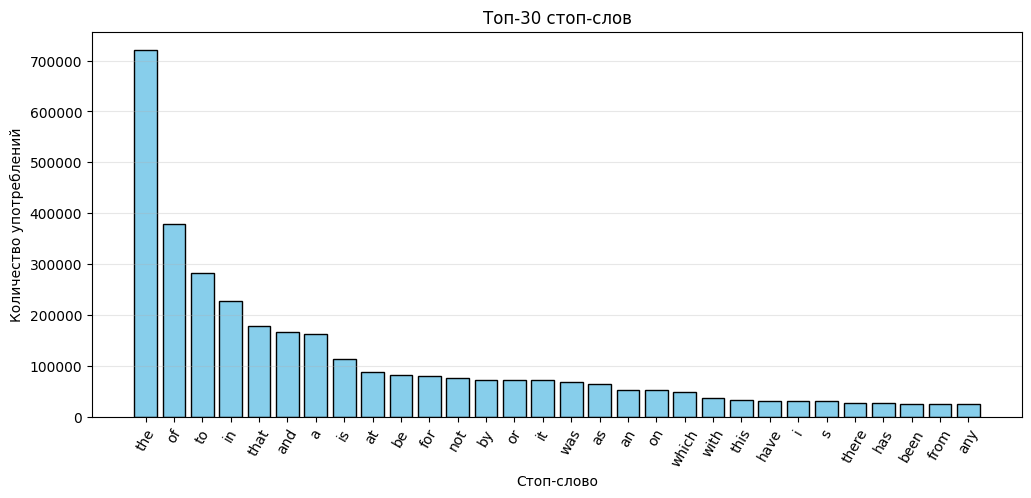

In [89]:
N = X_train.shape[0]
print(f'Всего документов: {N}')
L = X_train['text'].str.len().mean()
print(f'Средняя длина текстов в символах: {L:.0f}')
text_words_len = X_train['text'].apply(lambda x: len(str(x).split()))
LW = text_words_len.mean()
print(f'Средняя длина текстов в словах: {LW:.0f}')
plt.figure(figsize=(10, 5))
plt.hist(text_words_len, bins=50, color='skyblue', edgecolor='black')
plt.title('Распределение длин текстов (в словах)')
plt.xlabel('Количество слов')
plt.ylabel('Количество документов')
plt.grid(axis='y', alpha=0.75)
plt.show()
plt.figure(figsize=(10, 5))
plt.hist(X_train['text'].str.len(), bins=50, color='skyblue', edgecolor='black')
plt.title('Распределение длин текстов в символах')
plt.xlabel('Количество символов')
plt.ylabel('Количество документов')
plt.show()
stop_words_en = set(stopwords.words('english'))
words = X_train['text'].str.lower().str.split().explode()
top_stop_words = words[words.isin(stop_words_en)]
top_stop_words = top_stop_words.value_counts().head(30)
plt.figure(figsize=(12, 5))
plt.bar(top_stop_words.index, top_stop_words.values, color='skyblue', edgecolor='black')
plt.title('Топ-30 стоп-слов')
plt.xlabel('Стоп-слово')
plt.ylabel('Количество употреблений')
plt.xticks(rotation=60)
plt.grid(axis='y', alpha=0.3)
plt.show()

## Задание 3
### Исследование шумовых данных

 В ходе изучения структуры корпуса текстов были обнаружены шумовые данные, характерные для конкретно этого датасета. В частности:
 - ссылки на сайты (https://)
 - email адреса
 - спец. символы
 - числовые значения

 Так же к шумовым данным можем отнести xml теги, однако данный вид шума был удален при парсинге датасета



In [90]:
noise_patterns = {
    'URL': r'https?://\S+|www\.\S+',
    'Email': r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
    'Numbers': r'\b\d+(?:[.,]\d+)*\b',
    'Special characters': r'[^a-zA-Z0-9\s.,!?;:\-«»"' + "'" + r']'
}

for name, pattern in noise_patterns.items():
    count = X_train['text'].str.contains(
        pattern, regex=True, na=False
    ).sum()

    print(f'{name}: {count} документов')

URL: 864 документов
Email: 6 документов
Numbers: 20066 документов
Special characters: 20063 документов


## Задание 4
### Комплексный конвейер очистки

Была реализована функция для избавления от шумовых данных, описанных в п.3. Для удаления шума использовался модуль re

- Ссылки на сайты заменялись значением "[URL]"
- Почтовые адреса заменялись значением "[EMAIl]"
- Числа заменялись значением "[NUM]"
- Спецсимволы и лишние пробелы пропускались




In [91]:
def remove_noise(text:str) -> str:
    url_pattern = re.compile(r'https?://\S+|www\.\S+')
    mail_pattern = re.compile(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b')
    spec_pattern = re.compile(r'[^a-zA-Z0-9\s.,!?;:\-«»"' + "'" + r']')
    num_pattern = re.compile(r'\b\d+(?:[.,]\d+)*\b')
    spaces_pattern = re.compile(r'\s+')
    res = spec_pattern.sub('', text)
    res = url_pattern.sub('[URL]', res)
    res = mail_pattern.sub('[EMAIL]', res)
    res = num_pattern.sub('[NUM]', res)
    res = spaces_pattern.sub(' ', res).strip()
    return f"<s> {res} </s>"

## Задание 5

### Сравнительная нормализация

- Исходный словарь содержит 42 433 уникальных токена
- После стемминга размер словаря сократился до 29 585 токенов (на 30,3%)
- После лемматизации словарь сократился до 38 540 токенов (на 9,2%)
- Стемминг сильнее сокращает словарь, однако часто образует несуществующие словоформы, например `minister` → `minist`, `immigration` → `immigr`
- Лемматизация лучше сохраняет исходные формы слов, но в некоторых случаях оставляет слова без изменений, например `applied` и `recently`
- Для юридических текстов предпочтительнее лемматизация, поскольку важно сохранять точную терминологию и смысл слов

In [92]:
from nltk.stem import SnowballStemmer, WordNetLemmatizer

X_train['text'] = X_train['text'].apply(lambda x: remove_noise(str(x)))
corpus = X_train['text'].str.cat(sep='\n')
corpus = corpus.replace('<s>', '').replace('</s>', '')
corpus = corpus.replace('[NUM]', '').replace('[URL]', '').replace('[EMAIL]', '')
corpus = corpus.lower()
corpus = re.sub(r'[^a-zA-Z\s]', '', corpus)
tokens = word_tokenize(corpus)
filtered = [w for w in tokens if w.lower() not in stop_words_en]
stemmer = SnowballStemmer('english')
stemmed_corp = [stemmer.stem(w) for w in filtered]
lemmatizer = WordNetLemmatizer()
lemmatized_corp = [lemmatizer.lemmatize(w) for w in filtered]

original_vocab = len(set(tokens))
stemmed_vocab = len(set(stemmed_corp))
lemmatized_vocab = len(set(lemmatized_corp))

print(f'Исходный словарь: {original_vocab}')
print(f'После стемминга: {stemmed_vocab}')
print(f'После лемматизации: {lemmatized_vocab}')

compare = pd.DataFrame({'Токен': filtered, 'Стемминг': stemmed_corp, 'Лемматизация': lemmatized_corp})
print(compare.head(10))


Исходный словарь: 42433
После стемминга: 29585
После лемматизации: 38540
         Токен     Стемминг Лемматизация
0        szflm        szflm        szflm
1            v            v            v
2     minister       minist     minister
3  immigration       immigr  immigration
4  citizenship  citizenship  citizenship
5          fca          fca          fca
6     recently       recent     recently
7      applied        appli      applied
8        szjhm        szjhm        szjhm
9            v            v            v


## Задание 6

### Поиск опечаток через строковые метрики

- Реализован алгоритм Левенштейна с оптимизацией памяти за счёт хранения только двух строк матрицы вместо всей матрицы

- Для ускорения поиска похожих слов построен обратный индекс по вариантам слов с удалением до двух символов

- Найдены пары слов с расстоянием редактирования 1 или 2, топ-10 сформирован по произведению частот слов в корпусе

- В топе очень много юридических терминов и сокращений, например `ltd` — `pty`, `act` — `fca`, `hca` — `act`

- Все найденные пары не являются опечатками, а представляют собой самостоятельные слова или юридические сокращения

In [93]:
def levenshtein_distance(a:str, b:str):
  len_a, len_b = len(a), len(b)
  prev = list(range(len_b + 1))

  for i in range(1, len_a + 1):
    curr = [i] + [0] * len_b

    for j in range(1, len_b + 1):
      chi = a[i-1] != b[j-1]
      curr[j] = min(prev[j] + 1, curr[j-1] + 1, prev[j-1] + chi)

    prev = curr

  return prev[-1]



In [94]:
from collections import Counter, defaultdict

def get_deletions(word: str, max_dist: int = 2):
    variants = {word}
    current = {word}

    for _ in range(max_dist):
        current = {
            w[:i] + w[i+1:]
            for w in current
            for i in range(len(w))
        }
        variants.update(current)

    return variants


word_counts = Counter(
    w.lower() for w in filtered
    if len(w) >= 3 and w.isalpha()
)

words = list(word_counts.keys())

inverted_index = defaultdict(list)
top10 = {}

for word in words:
    variants = get_deletions(word)

    candidates = set()

    for variant in variants:
        candidates.update(inverted_index[variant])

    for candidate in candidates:
        if abs(len(word) - len(candidate)) > 2:
            continue

        distance = levenshtein_distance(word, candidate)

        if distance in (1, 2):
            top10[(word, candidate)] = (
                word_counts[word] * word_counts[candidate]
            )

    for variant in variants:
        inverted_index[variant].append(word)

top10 = sorted(
    top10.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for (a, b), count in top10:
    print(a, b, count)

ltd pty 997239888
may pty 530603832
act fca 482887401
law ltd 477022254
case made 470270406
hca act 469984074
per pty 462357624
may made 411620682
fcr act 371734842
could court 350305008


## Задание 7

### Построение N-граммной языковой модели

- На основе очищенной обучающей выборки построена триграммная языковая модель (N=3)

- Для токенизации использовался `word_tokenize` из NLTK, специальные токены сохранялись с помощью временных замен

- Сформирован явный словарь `vocab`, содержащий уникальные токены обучающего корпуса и специальный токен `[UNK]`

- Для построения модели рассчитаны частоты триграмм и соответствующих им биграммных контекстов

- Вероятности следующих слов вычисляются методом максимального правдоподобия (MLE) на основе частот N-грамм

- В случае, если соответствующей биграммы в тексте не встречалось, то приравниваем вероятность появления слова к нулю

In [104]:
corpus = X_train['text'].str.cat(sep='\n')
corpus = corpus.replace('<s>', ' STARTTOKEN STARTTOKEN ')
corpus = corpus.replace('</s>', ' ENDTOKEN ')
corpus = corpus.replace('[NUM]', ' NUMTOKEN ')
corpus = corpus.replace('[URL]', ' URLTOKEN ')
corpus = corpus.replace('[EMAIL]', ' EMAILTOKEN ')

tokens = word_tokenize(corpus)

special_tokens = {
    'STARTTOKEN': '<s>',
    'ENDTOKEN': '</s>',
    'NUMTOKEN': '[NUM]',
    'URLTOKEN': '[URL]',
    'EMAILTOKEN': '[EMAIL]'
}

tokens = [
    special_tokens.get(w, w)
    for w in tokens
]

vocab = set(tokens)
vocab.update({
    '<s>', '</s>', '[UNK]',
    '[NUM]', '[URL]', '[EMAIL]'
})

trigrams = [
    (tokens[i], tokens[i+1], tokens[i+2])
    for i in range(len(tokens) - 2)
    if tokens[i] != '</s>' and tokens[i+1] != '</s>'
]
bigram_counts = Counter(
    (w1, w2)
    for w1, w2, w3 in trigrams
)
trigram_counts = Counter(trigrams)

def get_trigram_probs(w1, w2, w3, vocab):
  w1 = w1 if w1 in vocab else '[UNK]'
  w2 = w2 if w2 in vocab else '[UNK]'
  w3 = w3 if w3 in vocab else '[UNK]'

  count_tr = trigram_counts[(w1, w2, w3)]
  count_bi = bigram_counts[(w1, w2)]

  if count_bi > 0:
    return count_tr / count_bi
  else:
    return 0.0


## Задание 8

### Сглаживание вероятностей и оценка Perplexity

- Реализовано сглаживание Лидстоуна с параметром `k=0.1`, позволяющее назначать ненулевые вероятности триграммам, отсутствующим в обучающей выборке

- Для оценки языковой модели реализована метрика Perplexity с использованием логарифма правдоподобия, что позволяет избежать численного переполнения

- Без сглаживания (MLE) значение Perplexity составило `inf`, поскольку в тестовой выборке встретились триграммы с нулевой вероятностью

- После применения сглаживания Лидстоуна значение Perplexity составило `413.70`

- Математически бесконечная перплексия MLE объясняется тем, что логарифм нулевой вероятности стремится к минус бесконечности

- Сглаживание позволило получить конечное значение Perplexity и обеспечить обработку ранее не встречавшихся триграмм


In [105]:
def lidstone_smoothing(w1, w2, w3, vocab, k=0.1):
  w1 = w1 if w1 in vocab else '[UNK]'
  w2 = w2 if w2 in vocab else '[UNK]'
  w3 = w3 if w3 in vocab else '[UNK]'

  count_tr = trigram_counts[(w1, w2, w3)]
  count_bi = bigram_counts[(w1, w2)]

  return (count_tr + k) / (count_bi + k * len(vocab))

In [106]:
import math
def perplexity(tokens, trigrams_count, bigrams_count, smoothing_flg):
  trigrams = [
    (tokens[i], tokens[i+1], tokens[i+2])
    for i in range(len(tokens) - 2)
    if tokens[i] != '</s>' and tokens[i+1] != '</s>'
  ]

  log_likelihood = 0

  for w1, w2, w3 in trigrams:
    if smoothing_flg:
      p = lidstone_smoothing(w1, w2, w3, vocab)
    else:
      p = get_trigram_probs(w1, w2, w3, vocab)

    if p == 0:
      return float('inf')

    log_likelihood += math.log(p)

  N = len(trigrams)

  return math.exp(-log_likelihood / N)

In [107]:
test_corpus = X_test['text'].apply(
    lambda x: remove_noise(str(x))
).str.cat(sep='\n')

test_corpus = test_corpus.replace('<s>', ' STARTTOKEN STARTTOKEN ')
test_corpus = test_corpus.replace('</s>', ' ENDTOKEN ')
test_corpus = test_corpus.replace('[NUM]', ' NUMTOKEN ')
test_corpus = test_corpus.replace('[URL]', ' URLTOKEN ')
test_corpus = test_corpus.replace('[EMAIL]', ' EMAILTOKEN ')

test_tokens = word_tokenize(test_corpus)

special_tokens = {
    'STARTTOKEN': '<s>',
    'ENDTOKEN': '</s>',
    'NUMTOKEN': '[NUM]',
    'URLTOKEN': '[URL]',
    'EMAILTOKEN': '[EMAIL]'
}

test_tokens = [
    special_tokens.get(w, w)
    for w in test_tokens
]

test_tokens = [
    w if w in vocab else '[UNK]'
    for w in test_tokens
]

In [108]:
print('MLE:', perplexity(test_tokens, trigram_counts, bigram_counts, False))
print('Lidstone:', perplexity(test_tokens, trigram_counts, bigram_counts, True))

MLE: inf
Lidstone: 413.7010509420494


## Задание 9

### Генерация текстов на основе Марковских цепей

- На основе триграммной модели реализована генерация случайных текстов с использованием Марковской цепи второго порядка

- Генерация начинается с двух токенов `<s>` и завершается при достижении `</s>` или максимальной длины последовательности

- Сгенерировано 5 текстов, в которых присутствуют характерные для юридической сферы термины и конструкции, например `Counsel`, `Section`, `The alleged error`

- Грамматическая связность текстов частичная: отдельные фрагменты построены корректно, однако встречаются нарушения структуры предложений и резкие переходы между конструкциями

- Смысловая связность отсутствует. Модель учитывает только два предыдущих слова и не способна поддерживать общий контекст
- Частое появление `[NUM]` связано с заменой числовых значений при очистке корпуса и их высокой частотой в начале юридических текстов. Вероятно в юридических корпусах присутсвует множество ссылок на регламентирующие документы, номера законов и т.д.

- В целом модель воспроизводит локальные закономерности юридического языка, но не обеспечивает генерацию полноценных осмысленных предложений

In [109]:
import random
def generate_text_trigram(max_length=25):
  w_prev2, w_prev1 = '<s>', '<s>'
  generated_words = []

  for _ in range(max_length):
      candidates = [
          tg[2]
          for tg in trigram_counts
          if tg[0] == w_prev2 and tg[1] == w_prev1
          and tg[2] != '<s>'
      ]

      if not candidates:
          break

      weights = [
          trigram_counts[(w_prev2, w_prev1, cand)]
          for cand in candidates
      ]

      next_word = random.choices(candidates, weights=weights)[0]

      if next_word == '</s>':
          break

      generated_words.append(next_word)

      w_prev2, w_prev1 = w_prev1, next_word

  return ' '.join(generated_words)

In [110]:
for _ in range(5):
  print(f" -> '{generate_text_trigram(max_length=25)}'")

 -> '[NUM] The discretion so as to the amount Network sued for publishing is not only when the trial can still be appropriate to explore the'
 -> '[NUM] While there is a serious matter . Counsel for the purpose of pre-grant opposition proceedings . It was said led to ABA 's decision'
 -> '[NUM] Section [NUM] provides a measure of damages in respect of the operation of s 177C1b , had not been properly considered s 190F6 .'
 -> '[NUM] Drawing on Deane and Gaudron JJ , CLR [NUM] at [NUM] [NUM] MLJ [NUM] at [NUM] : 'Where design purposes are recognised in Teoh'
 -> '[NUM] The majority of the Lebanese Armed Forces in May [NUM] , a long one ... The alleged error was insignificant ... The power to'
